# 03 · Evaluación final, sensibilidad y reducción de dimensión

¿Con qué fiabilidad se puede identificar una sesión que termina en compra? Continuamos la clasificación supervisada de `Revenue` con las particiones del 01 y las cinco configuraciones del 02. La proporción de compras da la referencia para precisión promedio (AP). Usamos validación para tomar decisiones y prueba para describir su efecto.

Sakar et al. (2019), Necula (2023), Satu e Islam (2023) y Lin (2025) estudiaron esta base con distintos métodos de balanceo y partición. Esa diferencia limita la comparación directa de sus cifras con las nuestras. La tabla resume los resultados publicados que recoge el [informe](../informe_entregable_II.pdf).

| Trabajo | Modelos y preparación | Evaluación | Resultado publicado |
|---|---|---|---|
| Sakar et al. (2019) | MLP, RF y SVM con sobremuestreo y selección de variables | El protocolo detallado no consta en la fuente consultada | MLP, exactitud 87,24 % y F1 0,86 |
| Necula (2023) | Regresión logística, árboles, RF y SVM con ADASYN y exploración mediante PCA | Diez pliegues y 25 % reservado para prueba | RF, ROC-AUC 0,9777 en CV y 0,8973 en prueba |
| Satu e Islam (2023) | RF, SVM, árboles y regresión logística con SMOTE, escalado y selección de variables | Diez pliegues en Weka | RF, exactitud 92,39 % y F1 0,924 |
| Lin (2025) | SVM, XGBoost, CatBoost y red neuronal con SMOTE y filtros de variables | Partición 80/20 con 50 semillas | CatBoost, precisión 0,934, recall 0,935 y ROC-AUC 0,985 |

La ejecución habitual vuelve a ajustar los cinco clasificadores y calcula sus curvas y umbrales. Recupera los intervalos, las comparaciones pareadas y los barridos costosos de la ejecución documentada en `resultados/`. Las dos opciones siguientes permiten repetir las búsquedas sin PageValues y de reducción sobre las particiones originales.

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve,
)
from sklearn.model_selection import cross_val_score
from threadpoolctl import threadpool_limits

from shopytics.models import construir_modelos
from shopytics.search import mallas_ampliadas
from shopytics.training import buscar_configuraciones, evaluar, pliegues, validar_finalistas

REPETIR_SIN_PAGEVALUES = False
REPETIR_REDUCCION = False

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = raiz / "data"
resultados = raiz / "resultados"
evaluacion = resultados / "evaluacion_familias"
reduccion = resultados / "reduccion"
entrenamiento = resultados / "entrenamiento"
manifiesto = json.loads((resultados / "manifiesto.json").read_text())
assert hashlib.sha256((datos / "online_shoppers_intention.csv").read_bytes()).hexdigest() == manifiesto["sha256_datos"]
particiones = pd.read_pickle(datos / "dataset_particiones.pkl")
X = {p: df.drop(columns="Revenue") for p, df in particiones.items()}
y = {p: df["Revenue"].astype(int) for p, df in particiones.items()}
tr, va, te = "entrenamiento", "validacion", "prueba"
mejores = pd.read_json(entrenamiento / "mejores_configuraciones.json").set_index("modelo")
familias = mejores.sort_values("AP", ascending=False).index
print("Semilla", manifiesto["semilla"], "· Versiones de la ejecución de referencia", manifiesto["versiones"])
display(pd.DataFrame({p: [len(y[p]), y[p].sum(), y[p].mean()] for p in y},
                     index=["Sesiones", "Compras", "Prevalencia"]).T)
display(mejores.loc[familias, ["params", "AP_CV", "AP"]])

Semilla 42 · Versiones de la ejecución de referencia {'numpy': '2.3.1', 'pandas': '2.3.1', 'scipy': '1.16.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.7', 'umap-learn': '0.6.0', 'numba': '0.68.1'}


,Sesiones,Compras,Prevalencia
entrenamiento,7323.0,1145.0,0.156357
validacion,2441.0,381.0,0.156084
prueba,2441.0,382.0,0.156493


,params,AP_CV,AP
modelo,,,
RandomForest,"{'clf__class_weight': None, 'clf__max_depth': ...",0.757273,0.741404
MLP,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.737548,0.722479
SVM,"{'clf__C': 30, 'clf__class_weight': None, 'clf...",0.725999,0.705417
kNN,"{'clf__n_neighbors': 81, 'clf__p': 2, 'clf__we...",0.717198,0.701832
Regresion_logistica,"{'clf__C': 0.1, 'clf__class_weight': None, 'pr...",0.689679,0.684086


## 1. Qué explica la selección del 02

El primer gráfico recupera la señal individual medida en entrenamiento. En los ocho paneles de la malla, cada punto promedia las configuraciones con ese valor del parámetro. Las barras muestran la dispersión entre los cinco promedios por pliegue.

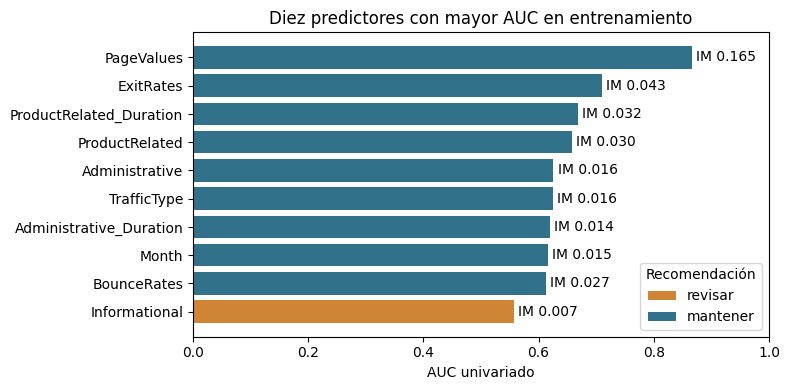

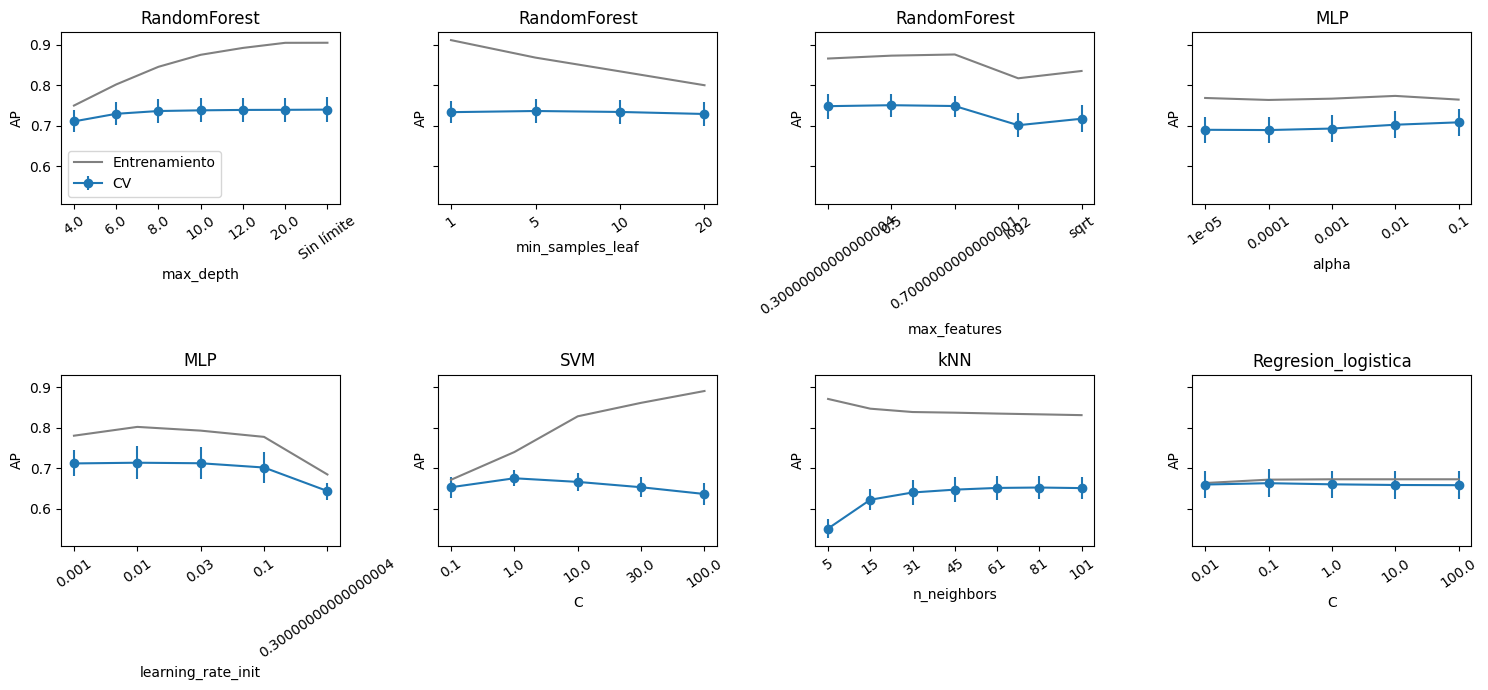

In [2]:
variables = pd.read_json(resultados / "variables" / "analisis_variables.json")
principales = variables.nlargest(10, "auc_univariado").sort_values("auc_univariado")
colores = {"mantener": "#31718a", "revisar": "#ce8534", "eliminar o combinar": "#a5a5a5"}
fig, ax = plt.subplots(figsize=(8, 4))
for recomendacion, grupo in principales.groupby("recomendacion", sort=False):
    posiciones = principales.index.get_indexer(grupo.index)
    barras = ax.barh(posiciones, grupo.auc_univariado, color=colores[recomendacion], label=recomendacion)
    ax.bar_label(barras, labels=[f"IM {valor:.3f}" for valor in grupo.informacion_mutua], padding=3)
ax.set(yticks=range(len(principales)), yticklabels=principales.variable,
       xlim=(0, 1), xlabel="AUC univariado", title="Diez predictores con mayor AUC en entrenamiento")
ax.legend(title="Recomendación", loc="lower right")
plt.tight_layout()
plt.show()

paneles = [("RandomForest", "max_depth"), ("RandomForest", "min_samples_leaf"),
           ("RandomForest", "max_features"), ("MLP", "alpha"), ("MLP", "learning_rate_init"),
           ("SVM", "C"), ("kNN", "n_neighbors"), ("Regresion_logistica", "C")]
fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for ax, (familia, parametro) in zip(axes.flat, paneles):
    cv = pd.read_json(entrenamiento / "cv" / f"{familia}.json")
    parametros = pd.json_normalize(cv["params"])
    if familia == "SVM":
        cv = cv.loc[parametros["clf__kernel"].eq("rbf")]
    grupos = cv.groupby(parametros["clf__" + parametro].fillna("Sin límite"))
    validacion = grupos[[f"split{i}_test_score" for i in range(5)]].mean()
    ajuste = grupos[[f"split{i}_train_score" for i in range(5)]].mean()
    etiquetas = validacion.index.astype(str)
    ax.errorbar(etiquetas, validacion.mean(axis=1), yerr=validacion.std(axis=1), fmt="o-", label="CV")
    ax.plot(etiquetas, ajuste.mean(axis=1), color="gray", label="Entrenamiento")
    ax.set(title=familia, xlabel=parametro, ylabel="AP")
    ax.tick_params(axis="x", rotation=35)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## 2. Rendimiento de las cinco familias

Ajustamos cada pipeline sobre entrenamiento. Las métricas de clasificación usan el umbral nativo. Para las curvas y AP usamos la puntuación continua, incluida la función de decisión de SVM.

AP  ROC_AUC  precision  recall      F1  \
modelo              particion                                                   
RandomForest        entrenamiento  0.8284   0.9573     0.7977  0.6541  0.7188   
                    validacion     0.7414   0.9265     0.7025  0.5827  0.6370   
                    prueba         0.7496   0.9302     0.7443  0.5942  0.6608   
MLP                 entrenamiento  0.7798   0.9429     0.7500  0.6341  0.6872   
                    validacion     0.7225   0.9242     0.7161  0.5958  0.6504   
                    prueba         0.7494   0.9284     0.7157  0.5864  0.6446   
SVM                 entrenamiento  0.7986   0.9386     0.7745  0.6480  0.7057   
                    validacion     0.7054   0.9001     0.7013  0.5669  0.6270   
                    prueba         0.7272   0.9034     0.7210  0.6021  0.6562   
kNN                 entrenamiento  1.0000   1.0000     1.0000  1.0000  1.0000   
                    validacion     0.7018   0.9124     0.7266  0.4882  0.5840   
                    prueba         0.6976   0.9075     0.7346  0.5000  0.5950   
Regresion_logistica entrenamiento  0.6987   0.9194     0.7141  0.5520  0.6227   
                    validacion     0.6841   0.9123     0.7170  0.5853  0.6445   
                    prueba         0.6956   0.9110     0.7143  0.5497  0.6213   

                                   balanced_accuracy  accuracy  
modelo              particion                                   
RandomForest        entrenamiento             0.8117    0.9200  
                    validacion                0.7685    0.8964  
                    prueba                    0.7782    0.9045  
MLP                 entrenamiento             0.7974    0.9097  
                    validacion                0.7761    0.9000  
                    prueba                    0.7716    0.8988  
SVM                 entrenamiento             0.8065    0.9155  
                    validacion                0.7611    0.8947  
                    prueba                    0.7794    0.9013  
kNN                 entrenamiento             1.0000    1.0000  
                    validacion                0.7271    0.8914  
                    prueba                    0.7332    0.8935  
Regresion_logistica entrenamiento             0.7555    0.8954  
                    validacion                0.7713    0.8992  
                    prueba                    0.7545    0.8951

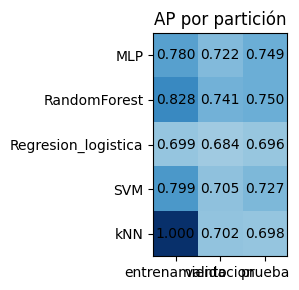

In [3]:
def puntuar(modelo, datos):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(datos)[:, 1]
    return modelo.decision_function(datos)

modelos = construir_modelos()
puntuaciones = {}
filas = []
with threadpool_limits(limits=1):
    for familia in familias:
        modelo = modelos[familia].set_params(**mejores.at[familia, "params"])
        modelo.fit(X[tr], y[tr])
        for p in particiones:
            puntuaciones[familia, p] = puntuar(modelo, X[p])
            filas.append({"modelo": familia, "particion": p, **evaluar(modelo, X[p], y[p])})

metricas = pd.DataFrame(filas).set_index(["modelo", "particion"])
display(metricas.round(4))
ap = metricas.AP.unstack()[[tr, va, te]]
fig, ax = plt.subplots(figsize=(6, 3))
ax.imshow(ap, cmap="Blues", vmin=0.5, vmax=1)
ax.set(xticks=range(3), xticklabels=ap.columns, yticks=range(len(ap)), yticklabels=ap.index, title="AP por partición")
for i, fila in enumerate(ap.to_numpy()):
    for j, valor in enumerate(fila):
        ax.text(j, i, f"{valor:.3f}", ha="center", va="center")
plt.tight_layout()
plt.show()

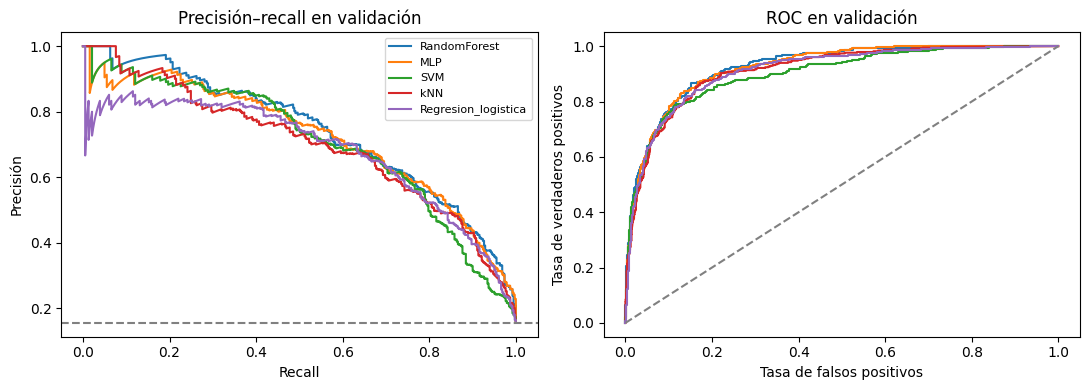

In [4]:
fig, (pr, roc) = plt.subplots(1, 2, figsize=(11, 4))
for familia in familias:
    scores = puntuaciones[familia, va]
    precision, recall, _ = precision_recall_curve(y[va], scores)
    fpr, tpr, _ = roc_curve(y[va], scores)
    pr.plot(recall, precision, label=familia)
    roc.plot(fpr, tpr)
pr.axhline(y[va].mean(), ls="--", color="gray")
roc.plot([0, 1], [0, 1], "--", color="gray")
pr.set(xlabel="Recall", ylabel="Precisión", title="Precisión–recall en validación")
roc.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="ROC en validación")
pr.legend(fontsize=8)
plt.tight_layout()
plt.show()

Los intervalos de CV usan la distribución *t* con cuatro grados de libertad. En las particiones, el bootstrap remuestrea por clase 2.000 veces con las predicciones fijas. Para comparar familias usa las mismas sesiones en cada réplica. Mostramos los intervalos de CV para AP, ROC-AUC y F1, los intervalos de AP por partición y las comparaciones de AP y ROC-AUC en prueba.

In [5]:
ic_cv = pd.read_csv(evaluacion / "cv_intervalos.csv")
ic = pd.read_csv(evaluacion / "intervalos.csv")
pares = pd.read_csv(evaluacion / "comparaciones_test.csv")
display(ic_cv.set_index(["modelo", "metrica"]).round(4))
display(ic.query("metrica == 'AP'").round(4))
display(ic.query("particion == 'test'").pivot(index="modelo", columns="metrica",
                                            values=["ic_inferior", "ic_superior"]).round(4))
display(pares.set_index(["modelo_a", "modelo_b", "metrica"]).round(4))

n_folds   media  desviacion  error_estandar  \
modelo              metrica                                                
RandomForest        AP             5  0.7573      0.0262          0.0117   
                    ROC_AUC        5  0.9340      0.0076          0.0034   
                    F1             5  0.6649      0.0343          0.0153   
MLP                 AP             5  0.7375      0.0382          0.0171   
                    ROC_AUC        5  0.9280      0.0101          0.0045   
                    F1             5  0.6391      0.0555          0.0248   
SVM                 AP             5  0.7260      0.0393          0.0176   
                    ROC_AUC        5  0.9032      0.0193          0.0086   
                    F1             5  0.6580      0.0498          0.0223   
kNN                 AP             5  0.7172      0.0259          0.0116   
                    ROC_AUC        5  0.9180      0.0095          0.0043   
                    F1             5  0.5760      0.0515          0.0230   
Regresion_logistica AP             5  0.6897      0.0357          0.0160   
                    ROC_AUC        5  0.9158      0.0085          0.0038   
                    F1             5  0.6164      0.0297          0.0133   

                             ic_inferior  ic_superior  
modelo              metrica                            
RandomForest        AP            0.7248       0.7898  
                    ROC_AUC       0.9245       0.9435  
                    F1            0.6224       0.7074  
MLP                 AP            0.6901       0.7850  
                    ROC_AUC       0.9155       0.9406  
                    F1            0.5702       0.7079  
SVM                 AP            0.6772       0.7748  
                    ROC_AUC       0.8793       0.9271  
                    F1            0.5961       0.7198  
kNN                 AP            0.6850       0.7494  
                    ROC_AUC       0.9061       0.9298  
                    F1            0.5121       0.6399  
Regresion_logistica AP            0.6453       0.7341  
                    ROC_AUC       0.9052       0.9264  
                    F1            0.5796       0.6533

,metrica,media_bootstrap,ic_inferior,ic_superior,modelo,particion
0,AP,0.8283,0.8105,0.8448,RandomForest,entrenamiento
7,AP,0.7427,0.7034,0.7786,RandomForest,validacion
14,AP,0.7505,0.7134,0.7869,RandomForest,test
21,AP,0.7799,0.7562,0.8010,MLP,entrenamiento
28,AP,0.7240,0.6808,0.7653,MLP,validacion
35,AP,0.7504,0.7127,0.7873,MLP,test
42,AP,0.7986,0.7767,0.8183,SVM,entrenamiento
49,AP,0.7072,0.6634,0.7490,SVM,validacion
56,AP,0.7282,0.6864,0.7689,SVM,test
63,AP,1.0000,1.0000,1.0000,kNN,entrenamiento


ic_inferior                                             \
metrica                      AP      F1 ROC_AUC accuracy balanced_accuracy   
modelo                                                                       
MLP                      0.7127  0.6040  0.9150   0.8882            0.7475   
RandomForest             0.7134  0.6211  0.9178   0.8947            0.7534   
Regresion_logistica      0.6541  0.5778  0.8950   0.8849            0.7288   
SVM                      0.6864  0.6161  0.8850   0.8906            0.7554   
kNN                      0.6561  0.5507  0.8923   0.8832            0.7077   

                                      ic_superior                           \
metrica             precision  recall          AP      F1 ROC_AUC accuracy   
modelo                                                                       
MLP                    0.6715  0.5392      0.7873  0.6838  0.9410   0.9095   
RandomForest           0.7006  0.5445      0.7869  0.6984  0.9430   0.9144   
Regresion_logistica    0.6688  0.5000      0.7396  0.6647  0.9272   0.9062   
SVM                    0.6785  0.5524      0.7689  0.6938  0.9212   0.9119   
kNN                    0.6875  0.4503      0.7392  0.6379  0.9232   0.9037   

                                                         
metrica             balanced_accuracy precision  recall  
modelo                                                   
MLP                            0.7962    0.7613  0.6361  
RandomForest                   0.8016    0.7886  0.6414  
Regresion_logistica            0.7807    0.7621  0.5995  
SVM                            0.8030    0.7675  0.6492  
kNN                            0.7580    0.7836  0.5497

diferencia_puntual  media_bootstrap  \
modelo_a     modelo_b            metrica                                        
RandomForest MLP                 AP                   0.0002           0.0002   
                                 ROC_AUC              0.0018           0.0019   
             SVM                 AP                   0.0224           0.0223   
                                 ROC_AUC              0.0268           0.0270   
             kNN                 AP                   0.0520           0.0515   
                                 ROC_AUC              0.0227           0.0226   
             Regresion_logistica AP                   0.0539           0.0531   
                                 ROC_AUC              0.0192           0.0191   
MLP          SVM                 AP                   0.0222           0.0221   
                                 ROC_AUC              0.0249           0.0251   
             kNN                 AP                   0.0518           0.0514   
                                 ROC_AUC              0.0209           0.0207   
             Regresion_logistica AP                   0.0537           0.0529   
                                 ROC_AUC              0.0174           0.0172   
SVM          kNN                 AP                   0.0296           0.0292   
                                 ROC_AUC             -0.0041          -0.0044   
             Regresion_logistica AP                   0.0316           0.0308   
                                 ROC_AUC             -0.0076          -0.0079   
kNN          Regresion_logistica AP                   0.0019           0.0015   
                                 ROC_AUC             -0.0035          -0.0035   

                                          ic_inferior  ic_superior  n_boot  
modelo_a     modelo_b            metrica                                    
RandomForest MLP                 AP           -0.0190       0.0190    2000  
                                 ROC_AUC      -0.0036       0.0075    2000  
             SVM                 AP            0.0001       0.0450    2000  
                                 ROC_AUC       0.0144       0.0406    2000  
             kNN                 AP            0.0304       0.0737    2000  
                                 ROC_AUC       0.0151       0.0307    2000  
             Regresion_logistica AP            0.0244       0.0812    2000  
                                 ROC_AUC       0.0107       0.0289    2000  
MLP          SVM                 AP            0.0068       0.0379    2000  
                                 ROC_AUC       0.0130       0.0382    2000  
             kNN                 AP            0.0293       0.0735    2000  
                                 ROC_AUC       0.0130       0.0295    2000  
             Regresion_logistica AP            0.0268       0.0801    2000  
                                 ROC_AUC       0.0091       0.0261    2000  
SVM          kNN                 AP            0.0036       0.0543    2000  
                                 ROC_AUC      -0.0200       0.0102    2000  
             Regresion_logistica AP            0.0051       0.0567    2000  
                                 ROC_AUC      -0.0224       0.0062    2000  
kNN          Regresion_logistica AP           -0.0272       0.0298    2000  
                                 ROC_AUC      -0.0141       0.0069    2000

## 3. ¿Qué cambia al elegir el umbral por F1?

Maximizamos F1 en validación. En caso de empate tomamos el menor umbral. Aplicamos ese valor en prueba y calculamos intervalos estratificados para precisión, recall, F1 y exactitud balanceada a partir de los conteos de la matriz de confusión.

umbral                precisión  \
modelo              regla                                                 
RandomForest        Nativo            0.500000  0.7443 [0.6994, 0.7873]   
                    F1 en validación  0.319528  0.6505 [0.6130, 0.6889]   
MLP                 Nativo            0.500000  0.7157 [0.6711, 0.7615]   
                    F1 en validación  0.433714  0.6818 [0.6411, 0.7225]   
SVM                 Nativo            0.000000  0.7210 [0.6774, 0.7662]   
                    F1 en validación -0.697044  0.6345 [0.5982, 0.6723]   
kNN                 Nativo            0.500000  0.7346 [0.6873, 0.7842]   
                    F1 en validación  0.398862  0.6547 [0.6126, 0.6970]   
Regresion_logistica Nativo            0.500000  0.7143 [0.6698, 0.7607]   
                    F1 en validación  0.317197  0.6337 [0.5939, 0.6727]   

                                                       recall  \
modelo              regla                                       
RandomForest        Nativo            0.5942 [0.5471, 0.6440]   
                    F1 en validación  0.7356 [0.6911, 0.7776]   
MLP                 Nativo            0.5864 [0.5366, 0.6361]   
                    F1 en validación  0.6675 [0.6230, 0.7147]   
SVM                 Nativo            0.6021 [0.5550, 0.6518]   
                    F1 en validación  0.7225 [0.6780, 0.7670]   
kNN                 Nativo            0.5000 [0.4503, 0.5497]   
                    F1 en validación  0.6204 [0.5732, 0.6702]   
Regresion_logistica Nativo            0.5497 [0.5000, 0.5995]   
                    F1 en validación  0.6885 [0.6440, 0.7356]   

                                         exactitud balanceada  \
modelo              regla                                       
RandomForest        Nativo            0.7782 [0.7541, 0.8040]   
                    F1 en validación  0.8311 [0.8087, 0.8532]   
MLP                 Nativo            0.7716 [0.7469, 0.7973]   
                    F1 en validación  0.8049 [0.7819, 0.8293]   
SVM                 Nativo            0.7794 [0.7548, 0.8044]   
                    F1 en validación  0.8226 [0.7997, 0.8459]   
kNN                 Nativo            0.7332 [0.7084, 0.7580]   
                    F1 en validación  0.7799 [0.7554, 0.8051]   
Regresion_logistica Nativo            0.7545 [0.7297, 0.7804]   
                    F1 en validación  0.8073 [0.7835, 0.8313]   

                                                           F1  
modelo              regla                                      
RandomForest        Nativo            0.6608 [0.6195, 0.7003]  
                    F1 en validación  0.6904 [0.6569, 0.7236]  
MLP                 Nativo            0.6446 [0.6030, 0.6865]  
                    F1 en validación  0.6746 [0.6381, 0.7110]  
SVM                 Nativo            0.6562 [0.6154, 0.6960]  
                    F1 en validación  0.6756 [0.6416, 0.7091]  
kNN                 Nativo            0.5950 [0.5508, 0.6373]  
                    F1 en validación  0.6371 [0.5987, 0.6756]  
Regresion_logistica Nativo            0.6213 [0.5786, 0.6638]  
                    F1 en validación  0.6600 [0.6239, 0.6954]

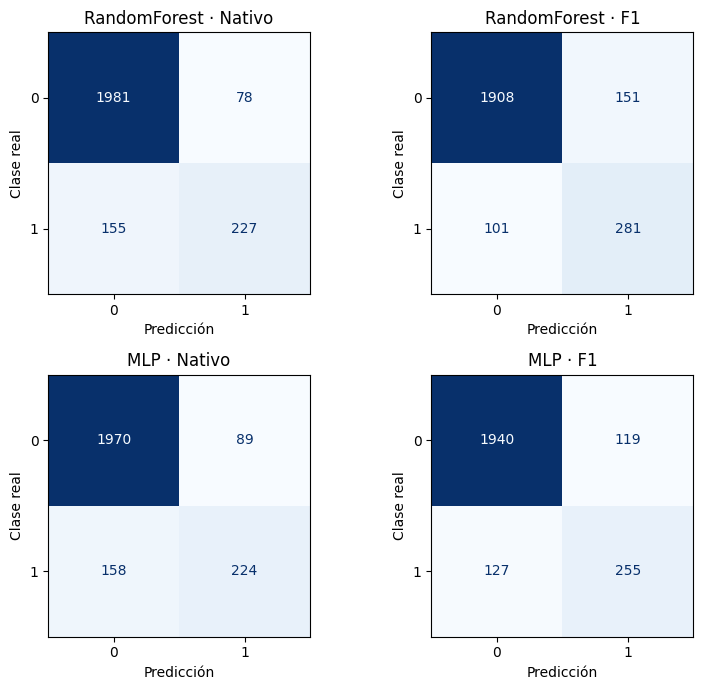

In [6]:
def resumen_umbral(y_real, scores, umbral):
    tn, fp, fn, tp = confusion_matrix(y_real, scores >= umbral, labels=[0, 1]).ravel()
    rng = np.random.default_rng(manifiesto["semilla"])
    # Dentro de cada clase, remuestrear las decisiones binarias da una binomial.
    tp_b = rng.binomial(tp + fn, tp / (tp + fn), 2000)
    fp_b = rng.binomial(tn + fp, fp / (tn + fp), 2000)
    aciertos, falsas = np.r_[tp, tp_b], np.r_[fp, fp_b]
    precision = np.divide(aciertos, aciertos + falsas, out=np.zeros(len(aciertos)), where=aciertos + falsas > 0)
    sensibilidad = aciertos / (tp + fn)
    especificidad = 1 - falsas / (tn + fp)
    medidas = {"precisión": precision, "recall": sensibilidad,
               "exactitud balanceada": (sensibilidad + especificidad) / 2,
               "F1": 2 * aciertos / (aciertos + falsas + tp + fn)}
    return {k: f"{v[0]:.4f} [{np.quantile(v[1:], .025):.4f}, {np.quantile(v[1:], .975):.4f}]"
            for k, v in medidas.items()}

umbrales = {}
filas = []
for familia in familias:
    precision, recall, cortes = precision_recall_curve(y[va], puntuaciones[familia, va])
    f1 = 2 * precision * recall / np.maximum(precision + recall, np.finfo(float).eps)
    umbrales[familia] = cortes[f1[:-1].argmax()]
    nativo = 0 if familia == "SVM" else 0.5
    for regla, corte in [("Nativo", nativo), ("F1 en validación", umbrales[familia])]:
        filas.append({"modelo": familia, "regla": regla, "umbral": corte,
                      **resumen_umbral(y[te], puntuaciones[familia, te], corte)})
display(pd.DataFrame(filas).set_index(["modelo", "regla"]))

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for familia, fila in zip(familias[:2], axes):
    for ax, (regla, corte) in zip(fila, [("Nativo", 0.5), ("F1", umbrales[familia])]):
        ConfusionMatrixDisplay.from_predictions(y[te], puntuaciones[familia, te] >= corte,
                                                colorbar=False, ax=ax, cmap="Blues")
        ax.set(title=f"{familia} · {regla}", xlabel="Predicción", ylabel="Clase real")
plt.tight_layout()
plt.show()

En Random Forest el umbral elegido recupera 54 compras adicionales en prueba (227 a 281) y produce 73 falsos positivos adicionales (78 a 151). La conveniencia de ese cambio depende del coste de contactar a un visitante y del valor de detectar una compra.

## 4. Sensibilidad a PageValues y SpecialDay

Para PageValues repetimos el protocolo del 02 sin esa columna. Cada familia vuelve a competir en su malla y se elige por AP de validación entre sus tres finalistas de CV. La ruta habitual lee los quince finalistas del barrido archivado.

In [7]:
if REPETIR_SIN_PAGEVALUES:
    modelos_sin = construir_modelos(incluir_pagevalues=False)
    _, mallas = mallas_ampliadas()
    tablas = []
    with threadpool_limits(limits=1):
        for familia, modelo in modelos_sin.items():
            cv = buscar_configuraciones(modelo, mallas[familia], X[tr], y[tr])
            tabla = validar_finalistas(modelo, cv, X[tr], y[tr], X[va], y[va])
            tablas.append(tabla.assign(modelo=familia))
    finalistas = pd.concat(tablas, ignore_index=True)
else:
    finalistas = pd.read_csv(resultados / "validacion_top3_sin_pagevalues.csv")

sin_pv = finalistas.loc[finalistas.groupby("modelo").AP.idxmax()].set_index("modelo")
pv = mejores[["AP"]].rename(columns={"AP": "AP_con"}).join(
    sin_pv[["AP", "ROC_AUC", "params"]].rename(columns={"AP": "AP_sin", "ROC_AUC": "ROC_AUC_sin"}))
display(pv.assign(delta_con_menos_sin=pv.AP_con - pv.AP_sin).round(4))

,AP_con,AP_sin,ROC_AUC_sin,params,delta_con_menos_sin
modelo,,,,,
RandomForest,0.7414,0.3848,0.7847,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.3566
MLP,0.7225,0.3532,0.7653,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.3693
SVM,0.7054,0.3403,0.7685,"{'clf__C': 1, 'clf__class_weight': 'balanced',...",0.3652
kNN,0.7018,0.3477,0.7615,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__w...",0.3541
Regresion_logistica,0.6841,0.3345,0.7616,"{'clf__C': 0.1, 'clf__class_weight': None, 'pr...",0.3496


En SpecialDay fijamos la configuración del 02 para aislar dos cambios distintos. Medimos el efecto de quitar la columna y el de pasar de proximidad numérica a one-hot. Los seis niveles equidistantes tienen la misma representación estandarizada si se codifican por rango ordinal. Completamos la comparación con el AP mensual del ganador en validación.

In [8]:
sin_sd = construir_modelos(incluir_specialday=False)
onehot = construir_modelos(codificar_specialday="onehot")
filas = []
with threadpool_limits(limits=1):
    for familia in familias:
        variantes = {"sin": sin_sd[familia], "onehot": onehot[familia]}
        fila = {"modelo": familia, "numérico": metricas.at[(familia, va), "AP"]}
        for nombre, modelo in variantes.items():
            modelo.set_params(**mejores.at[familia, "params"]).fit(X[tr], y[tr])
            fila[nombre] = average_precision_score(y[va], puntuar(modelo, X[va]))
        filas.append(fila)
sd = pd.DataFrame(filas).set_index("modelo")
sd["con_menos_sin"] = sd["numérico"] - sd["sin"]
sd["onehot_menos_numérico"] = sd["onehot"] - sd["numérico"]
codificacion = pd.read_csv(resultados / "specialday_codificacion.csv").set_index("modelo")
display(sd.join(codificacion[["AP_CV_numerico", "AP_CV_onehot"]]).round(4))
ganador = familias[0]
mensual = pd.DataFrame({"mes": X[va]["Month"], "compra": y[va], "score": puntuaciones[ganador, va]})
filas = [{"mes": mes, "sesiones": len(grupo), "compras": grupo.compra.sum(),
          "AP": average_precision_score(grupo.compra, grupo.score) if grupo.compra.any() else np.nan}
         for mes, grupo in mensual.groupby("mes")]
display(pd.DataFrame(filas).set_index("mes").round(4))

,numérico,sin,onehot,con_menos_sin,onehot_menos_numérico,AP_CV_numerico,AP_CV_onehot
modelo,,,,,,,
RandomForest,0.7414,0.7418,0.7418,-0.0004,0.0004,0.7573,0.7556
MLP,0.7225,0.7181,0.7322,0.0044,0.0097,0.7375,0.7365
SVM,0.7054,0.7040,0.6988,0.0014,-0.0066,0.7260,0.7287
kNN,0.7018,0.7066,0.7065,-0.0048,0.0046,0.7172,0.7216
Regresion_logistica,0.6841,0.6845,0.6835,-0.0004,-0.0006,0.6897,0.6907


,sesiones,compras,AP
mes,,,
Aug,76,8,0.5680
Dec,334,41,0.7670
Feb,37,0,NaN
Jul,96,15,0.5983
June,58,7,0.6900
Mar,359,38,0.7853
May,663,74,0.8769
Nov,633,166,0.6826
Oct,98,15,0.5891


## 5. PCA y UMAP en las dos familias mejor clasificadas

La base tiene 73 columnas después de la codificación. Para cada candidato, la validación cruzada ajusta el preprocesador y el reductor dentro de cada pliegue. UMAP aprende únicamente de los predictores. La variante PCA de 0,95 retiene el 95 % de varianza y puede tener distinta dimensión efectiva en cada ajuste.

In [9]:
from itertools import product
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

def barrer_reduccion():
    from umap import UMAP

    class UMAPSinEtiquetas(UMAP):
        def fit_transform(self, X, y=None):
            self.fit(X)
            return self.transform(X)

    filas = []
    for familia in familias[:2]:
        candidatos = [("PCA", n, None, PCA(n_components=n, svd_solver="full"))
                      for n in [5, 10, 15, 20, 28, 35, 45, 0.95]]
        candidatos += [("UMAP", n, k, UMAPSinEtiquetas(n_components=n, n_neighbors=k,
                                                        min_dist=0.1, random_state=42,
                                                        compatibility_layout=True))
                       for n, k in product([2, 5, 10, 15, 20], [15, 30, 50])]
        for metodo, n, k, reductor in candidatos:
            base = clone(modelos[familia])
            pipe = Pipeline([("pre", base["pre"]), ("reduccion", reductor), ("clf", base["clf"])])
            folds = cross_val_score(pipe, X[tr], y[tr], scoring="average_precision", cv=pliegues(),
                                    error_score="raise")
            pipe.fit(X[tr], y[tr])
            filas.append({"modelo": familia, "metodo": metodo, "dimensiones_solicitadas": n,
                          "componentes": reductor.n_components_ if metodo == "PCA" else n,
                          "vecinos": k, "AP_CV": folds.mean(), "std_CV": folds.std(),
                          "AP": average_precision_score(y[va], puntuar(pipe, X[va]))})
    return pd.DataFrame(filas)

if REPETIR_REDUCCION:
    with threadpool_limits(limits=1):
        barrido = barrer_reduccion()
else:
    barrido = pd.read_csv(reduccion / "reduccion_validacion.csv").query("metodo in ['PCA', 'UMAP']")

def elegir_1se(grupo):
    mejor = grupo.loc[grupo.AP.idxmax()]
    corte = mejor.AP - mejor.std_CV / np.sqrt(5)
    elegibles = grupo.loc[grupo.AP >= corte - 1e-12]
    return elegibles.sort_values(["componentes", "AP"], ascending=[True, False]).iloc[0]

elegidos = pd.DataFrame([elegir_1se(grupo) for _, grupo in barrido.groupby(["modelo", "metodo"])])
columnas = ["modelo", "metodo", "componentes", "vecinos", "AP_CV", "AP"]
display(elegidos[columnas].round(4))

,modelo,metodo,componentes,vecinos,AP_CV,AP
28,MLP,PCA,15.0,NaN,0.7368,0.7219
38,MLP,UMAP,5.0,30.0,0.6739,0.6484
2,RandomForest,PCA,10.0,NaN,0.7198,0.7074
20,RandomForest,UMAP,15.0,50.0,0.6980,0.6959


La regla 1-SE admite candidatos a un error estándar del mejor AP de validación y elige la menor dimensión elegible. Los siguientes gráficos muestran cuánto cuesta comprimir, cómo cambia la validación con la dimensión y qué solapamiento de clases queda en dos dimensiones.

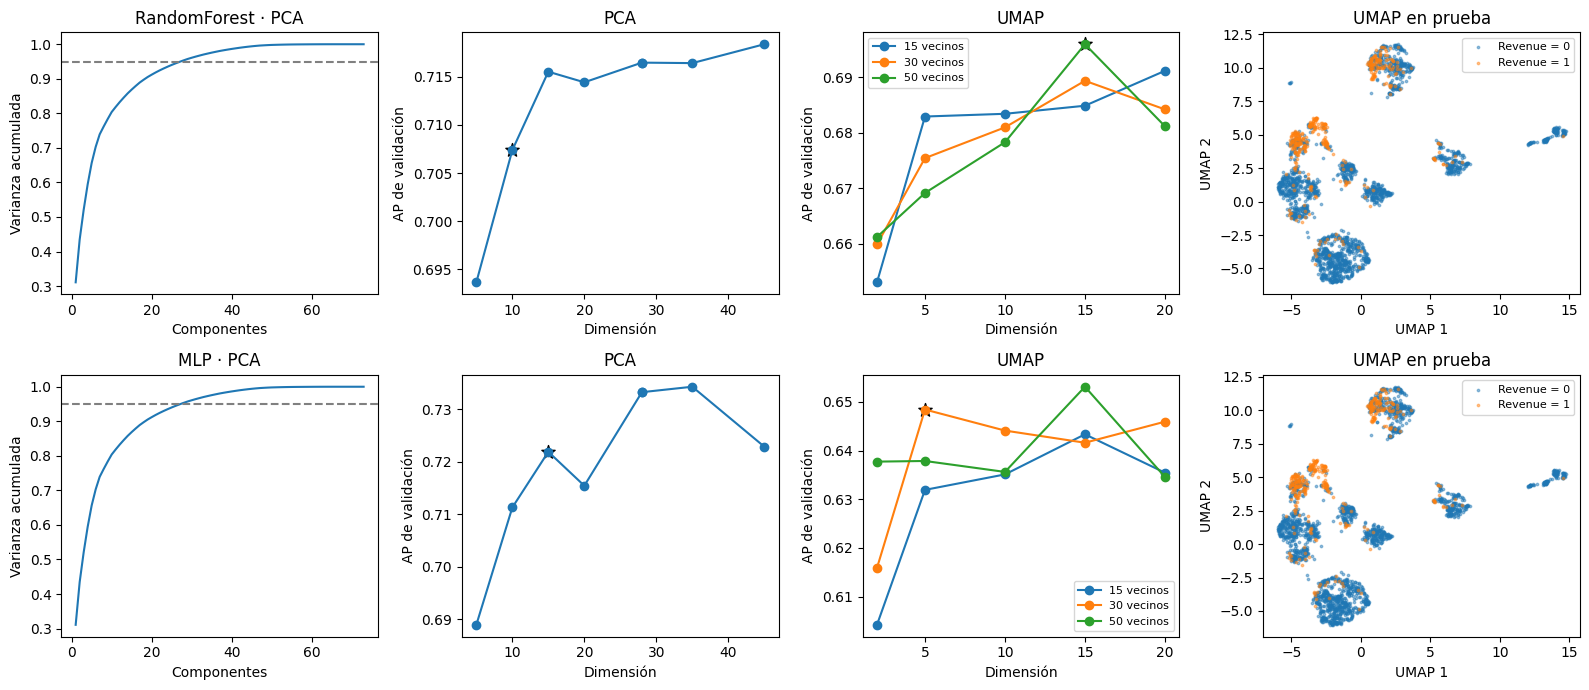

In [10]:
varianza = pd.read_csv(reduccion / "pca_varianza.csv")
proyeccion = pd.read_csv(reduccion / "umap2d_test.csv")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for familia, (ax_var, ax_pca, ax_umap, ax_2d) in zip(familias[:2], axes):
    curva = varianza.loc[varianza.modelo == familia]
    ax_var.plot(curva.componente, curva.varianza_acumulada)
    ax_var.axhline(.95, ls="--", color="gray")
    ax_var.set(title=f"{familia} · PCA", xlabel="Componentes", ylabel="Varianza acumulada")
    candidatos = barrido.loc[barrido.modelo == familia]
    pca = candidatos.query("metodo == 'PCA'").sort_values("componentes")
    ax_pca.plot(pca.componentes, pca.AP, "o-")
    for k, grupo in candidatos.query("metodo == 'UMAP'").groupby("vecinos"):
        grupo = grupo.sort_values("componentes")
        ax_umap.plot(grupo.componentes, grupo.AP, "o-", label=f"{k:g} vecinos")
    for metodo, ax in [("PCA", ax_pca), ("UMAP", ax_umap)]:
        punto = elegidos.query("modelo == @familia and metodo == @metodo")
        ax.scatter(punto.componentes, punto.AP, marker="*", color="black", s=100)
        ax.set(title=metodo, xlabel="Dimensión", ylabel="AP de validación")
    ax_umap.legend(fontsize=8)
    for clase, grupo in proyeccion.query("modelo == @familia").groupby("y_true"):
        ax_2d.scatter(grupo.x, grupo.y, s=3, alpha=.45, label=f"Revenue = {clase}")
    ax_2d.set(title="UMAP en prueba", xlabel="UMAP 1", ylabel="UMAP 2")
    ax_2d.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Evaluación de las variantes fijadas

En prueba comparamos la base, la variante seleccionada de cada método y la proyección UMAP 2D. La diferencia pareada de AP cuantifica el efecto de la reducción sobre las mismas sesiones.

In [11]:
prueba_red = pd.read_csv(reduccion / "reduccion_test.csv")
claves = ["modelo", "metodo", "componentes", "vecinos"]
variantes_en_prueba = prueba_red.query("metodo in ['PCA', 'UMAP']")
pd.testing.assert_frame_equal(elegidos[claves].sort_values(claves).reset_index(drop=True),
                              variantes_en_prueba[claves].sort_values(claves).reset_index(drop=True),
                              check_dtype=False)
resumen = prueba_red[claves + ["AP", "ic_AP_inferior", "ic_AP_superior", "ROC_AUC", "F1"]]
display(resumen.round(4))

diferencias = pd.read_csv(reduccion / "reduccion_comparacion.csv")
display(diferencias.set_index(["modelo", "metodo", "metrica"])[
    ["diferencia_puntual", "ic_inferior", "ic_superior"]
].sort_index().round(4))

,modelo,metodo,componentes,vecinos,AP,ic_AP_inferior,ic_AP_superior,ROC_AUC,F1
0,RandomForest,PCA,10.0,NaN,0.7236,0.6831,0.7626,0.9134,0.6145
1,RandomForest,UMAP,15.0,50.0,0.6879,0.6478,0.7292,0.8936,0.5927
2,RandomForest,UMAP2D,2.0,15.0,0.6595,0.6190,0.7019,0.8883,0.5488
3,RandomForest,Base,NaN,NaN,0.7496,0.7134,0.7869,0.9302,0.6608
4,MLP,PCA,15.0,NaN,0.7408,0.7027,0.7803,0.9255,0.6424
5,MLP,UMAP,5.0,30.0,0.6381,0.5960,0.6830,0.8620,0.5131
6,MLP,UMAP2D,2.0,15.0,0.5815,0.5366,0.6370,0.8522,0.5549
7,MLP,Base,NaN,NaN,0.7494,0.7127,0.7873,0.9284,0.6446


diferencia_puntual  ic_inferior  ic_superior
modelo       metodo metrica                                              
MLP          PCA    AP                  -0.0086      -0.0219       0.0050
                    ROC_AUC             -0.0029      -0.0084       0.0030
             UMAP   AP                  -0.1113      -0.1406      -0.0815
                    ROC_AUC             -0.0663      -0.0823      -0.0511
             UMAP2D AP                  -0.1679      -0.2042      -0.1237
                    ROC_AUC             -0.0762      -0.0944      -0.0585
RandomForest PCA    AP                  -0.0260      -0.0438      -0.0090
                    ROC_AUC             -0.0167      -0.0246      -0.0093
             UMAP   AP                  -0.0616      -0.0893      -0.0353
                    ROC_AUC             -0.0365      -0.0485      -0.0248
             UMAP2D AP                  -0.0900      -0.1181      -0.0617
                    ROC_AUC             -0.0418      -0.0550      -0.0293

## 6. Conclusiones y alcance

- **Selección.** Random Forest gana en validación (AP 0,7414). En prueba alcanza 0,7496 frente a 0,7494 de MLP. El intervalo pareado de la diferencia incluye cero. La evidencia deja margen para elegir entre ambas familias según el coste operativo.
- **Disponibilidad de variables.** Sin PageValues, aun reajustando la malla, el AP de validación de Random Forest cae a 0,3848. Para actuar durante una sesión haría falta evaluar predictores disponibles en el instante de la decisión. Los cambios al retirar SpecialDay son pequeños y dependen de la familia.
- **Simplificación.** En el 02, quitar seis predictores de bajo AUC individual dejó el AP de validación de RF prácticamente igual y mejoró el de MLP. Aquí, el 95 % de varianza requiere 28 componentes, mientras que la regla predictiva selecciona 10 para RF y 15 para MLP. UMAP pierde AP en prueba frente a ambas bases y la proyección 2D muestra solapamiento entre compradores y visitantes sin compra.
- **Límites.** Los intervalos condicionados a modelos y predicciones fijos omiten la variación que introducirían otra partición, otro entrenamiento o una nueva selección.
- **Generalización.** La evaluación usa una sola base y una sola semilla. Faltan enero y abril, y en febrero la partición de validación carece de compras. Los meses con pocas sesiones dan estimaciones de AP imprecisas. Una partición temporal y la repetición con otras semillas permitirían estudiar la estabilidad.
- **Uso del umbral.** La selección por F1 asigna el mismo peso a precisión y recall. Para decidir una intervención comercial habría que medir el coste de los errores y evaluar la calibración de las probabilidades.
- **Reducción.** PCA y UMAP reciben las variables numéricas estandarizadas y las indicadoras 0/1 sin escalar. La proyección de UMAP depende también de su inicialización. En MLP con PCA, los intervalos pareados de ΔAP y ΔROC-AUC incluyen cero.